# Lecture 27, Droughts II: theory of runs, drought frequency, climate change and management in India

> Turning an index into drought events, asking how often they come back, how warming changes them, and how India declares and manages them

Lecture 26 gave us drought indices: a number for every month that says how dry it was. A manager needs more: *when did the drought start and end, how much water was missing in total, and how often should we expect a drought this bad?* The **theory of runs** of Yevjevich (1967) answers the first two questions, simple frequency analysis the third. We then see how a warmer climate makes droughts worse even without less rain, and how the Government of India declares and manages a drought.

By the end of this lecture you should be able to:

- identify drought events in a monthly series with a threshold and compute their duration $D$, severity $S$, intensity $I$ and inter-arrival time $L$,
- estimate the return period of a drought from the record and from a fitted exponential distribution,
- explain, with the SPEI, why warming makes droughts more severe even when rainfall is unchanged,
- describe the indicators, triggers and roles in India's Manual for Drought Management.

The workbook `data/extremes/lec27/lec27_worked_examples.xlsx` repeats the hand example (sheet `Runs`) and the frequency analysis of the Chattooga streamflow droughts (sheet `Frequency`). The running dataset is the Chattooga River record of Lectures 7, 10 and 26.

In [1]:
# Google Colab setup: install the packages this notebook uses.
# Runs only on Colab; skipped in Binder or a local Jupyter install.
import sys
if "google.colab" in sys.modules:
    %pip install -q numpy pandas scipy matplotlib

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from scipy.special import gamma as gamma_fn

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False})

## Words you need

- **Threshold** $x_0$: the line that separates "drought" from "not drought", for example SPI $=-1$ or a low flow.
- **Run**: an unbroken sequence of months on the same side of the threshold. A *negative run* (below the threshold) is a drought event.
- **Deficit**: how far one month falls below the threshold, $x_0-x_t$. Adding the deficits of a run gives the **severity**.
- **Percentile and Q80**: the flow that is exceeded in 80 % of months (the 20th percentile of the flows). It is a common low-flow threshold.
- **Return period** $T$: the average time between events at least as severe as a given one. "A 25-year drought" is expected once in 25 years on average, not once every 25 years like a clock.
- **Exponential distribution**: the simplest curve for positive amounts where small values are common and large ones rare; it has one parameter, its mean (Lecture 17).
- **Copula**: a tool that joins two distributions (here duration and severity) into one joint probability. We only name it.

## Notation

The run symbols follow Yevjevich (1967) and Mishra & Singh (2010); the index symbols are those of Lecture 26.

| Symbol | Meaning | Units | Code / spreadsheet |
|:--|:--|:--|:--|
| $x_t$ | the drought variable in month $t$ (SPI-3, or monthly flow) | -, mm | `x` |
| $x_0$ | threshold | -, mm | `x0` |
| $j$ | event number | - | `j` |
| $D_j$ | duration: number of months in run $j$ | months | `D` |
| $S_j$ | severity: cumulative deficit, $\sum (x_0-x_t)$ over the run | -, mm | `S` |
| $I_j$ | intensity, $S_j/D_j$ | -, mm/month | `I` |
| $L_j$ | inter-arrival time: months from the start of event $j$ to the start of event $j+1$ | months | `L` |
| $t_c$ | pooling gap: events separated by $t_c$ months or less are merged | months | `tc` |
| $N_y$, $n_e$ | record length; number of events | years, - | `Ny`, `ne` |
| $\lambda=n_e/N_y$ | events per year | 1/yr | `lam` |
| $m$ | number of events with severity at least $s$ | - | `m` |
| $T$ | return period | years | `T` |
| $\bar S$ | mean severity, the exponential parameter | -, mm | `S_bar` |
| $s_T$ | $T$-year severity | -, mm | `s_T` |
| $W=P-PET$, $\Delta T$ | water balance (Lecture 26); warming | mm, degC | `W`, `dT` |

For flow, $x_t$ is the monthly runoff depth in mm, so $S$ is a missing water depth over the catchment; 1 mm over 536 km2 is 0.536 million m3.

## 1) The theory of runs

Yevjevich (1967) proposed a simple way to cut a time series into events. Draw a horizontal line at the threshold $x_0$. Every unbroken stretch of months **below** the line is a drought event (a negative run). For event $j$:

- **duration** $D_j$ = the number of months in the run,
- **severity** $S_j$ = the sum of the monthly deficits,

$$S_j=\sum_{t\,\in\,\text{run } j}\left(x_0-x_t\right),$$

- **intensity** $I_j=S_j/D_j$, the average deficit per month,
- **inter-arrival time** $L_j$ = the time from the start of one event to the start of the next.

The choice of $x_0$ decides everything. With the SPI, $x_0=-1$ (moderately dry) is common, and $x_0=0$ is also used. With flow, a fixed low-flow percentile such as Q80 or Q90 is common; a threshold that changes with the calendar month is a refinement used when the seasonal cycle is strong.

Two practical rules. **Pooling:** two runs separated by a short wet spell (here $t_c=1$ month or less) are really one drought, so they are merged; the merged event runs from the start of the first to the end of the second, and its severity is the sum of the two severities (the inter-event time method). **Minor events:** one-month runs with a tiny deficit are often dropped, because they inflate the number of events without mattering.

```{admonition} Worked example (by hand): drought events in 18 months of runoff
:class: tip

**Problem.** Monthly runoff (mm) of an invented small catchment, months $t=1$ to 18: **52, 41, 27, 22, 35, 48, 60, 33, 26, 18, 12, 21, 29, 44, 38, 24, 31, 55**. The threshold is $x_0=30$ mm. Find the drought events, their $D$, $S$, $I$ and $L$, the largest event, and its empirical return period. (Workbook: sheet `Runs`.)

**Step 1, mark the months below the threshold.** *Why:* these are the drought months. Below 30 mm: $t=3$ (27), 4 (22), 9 (26), 10 (18), 11 (12), 12 (21), 13 (29) and 16 (24).

**Step 2, group them into runs.** *Why:* an event is an unbroken stretch. Run 1 = months 3 to 4; run 2 = months 9 to 13; run 3 = month 16. The gaps between them (4 and 2 months) are longer than $t_c=1$, so nothing is pooled.

**Step 3, deficits $x_0-x_t$ and severity.**
Event 1: $(30-27)+(30-22)=3+8=11$ mm.
Event 2: $(30-26)+(30-18)+(30-12)+(30-21)+(30-29)=4+12+18+9+1=44$ mm.
Event 3: $30-24=6$ mm.

**Step 4, duration and intensity.** Event 1: $D=2$, $I=11/2=5.5$ mm/month. Event 2: $D=5$, $I=44/5=8.8$ mm/month. Event 3: $D=1$, $I=6/1=6.0$ mm/month.

**Step 5, inter-arrival times.** Starts at $t=3$, 9, 16, so $L_1=9-3=6$ and $L_2=16-9=7$ months.

**Step 6, the largest event.** Event 2 is the longest, the most severe and the most intense: 5 months, 44 mm, 8.8 mm/month.

**Step 7, empirical return period.** *Why:* how often is an event at least this severe? With record length $N_y=18/12=1.5$ years and $m$ events with $S\ge s$, $T=N_y/m$. For $s=44$ mm, $m=1$ and $T=1.5$ years; for $s=11$ mm, $m=2$ and $T=0.75$ years. (A record of 18 months is far too short for real frequency work; the point is the arithmetic.)
```

In [3]:
def runs(x, x0):
    """Theory of runs: drought events (negative runs below x0) of a monthly series with its date index."""
    x = x.dropna(); below = (x < x0).values
    events, t = [], 0
    while t < len(x):
        if below[t]:
            u = t
            while u + 1 < len(x) and below[u + 1]:
                u += 1
            events.append({"start": x.index[t], "end": x.index[u], "D": u - t + 1, "S": float(np.sum(x0 - x.values[t:u + 1]))})
            t = u + 1
        else:
            t += 1
    ev = pd.DataFrame(events)
    ev["I"] = ev.S / ev.D
    return ev

# Hand example: months 1..18 as the index
x_hand = pd.Series([52, 41, 27, 22, 35, 48, 60, 33, 26, 18, 12, 21, 29, 44, 38, 24, 31, 55.0], index=range(1, 19))
ev_hand = runs(x_hand, 30.0)
ev_hand["L"] = ev_hand.start.shift(-1) - ev_hand.start            # inter-arrival time (months)
Ny = len(x_hand) / 12
ev_hand["T_emp"] = [Ny / (ev_hand.S >= s).sum() for s in ev_hand.S]
print(ev_hand.round(2).to_string(index=False))

 start  end  D    S   I   L  T_emp
     3    4  2 11.0 5.5 6.0   0.75
     9   13  5 44.0 8.8 7.0   1.50
    16   16  1  6.0 6.0 NaN   0.50


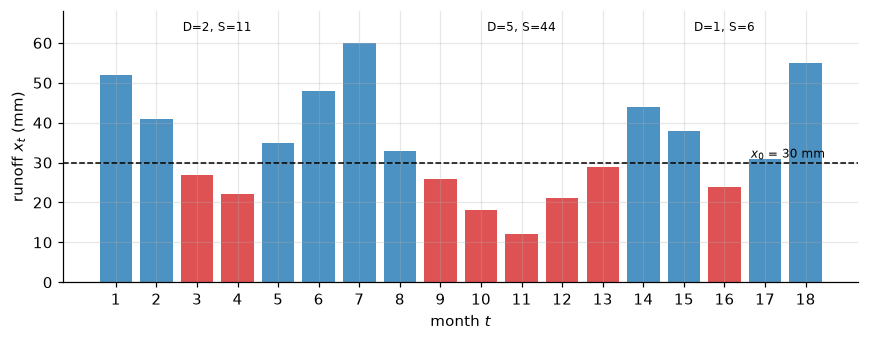

In [4]:
# Figure 1: the hand example
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.bar(x_hand.index, x_hand.values, color=np.where(x_hand < 30, "tab:red", "tab:blue"), alpha=0.8)
ax.axhline(30, color="k", lw=1, ls="--"); ax.text(18.5, 31, "$x_0$ = 30 mm", ha="right", fontsize=8)
for _, e in ev_hand.iterrows():
    ax.annotate(f"D={int(e.D)}, S={e.S:.0f}", ((e.start + e.end) / 2, 63), ha="center", fontsize=8)
ax.set_xlabel("month $t$"); ax.set_ylabel("runoff $x_t$ (mm)"); ax.set_xticks(x_hand.index); ax.set_ylim(0, 68)
plt.tight_layout(); plt.show()

## 2) Drought events on the Chattooga

We apply the runs to two variables from Lecture 26: the **SPI-3** with $x_0=-1$ (meteorological drought) and the **monthly runoff** with $x_0=$ Q80 (hydrological drought). The SPI code is the one of Lecture 26.

In [5]:
df = pd.read_csv("data/chattooga_daily.csv", comment="#", parse_dates=["date"], index_col="date")
mon = df.resample("MS").agg({"prcp_mm": "sum", "tmean_c": "mean", "pet_mm": "sum", "q_mm": "sum"})

def spi_values(x):                       # Lecture 26: Thom's gamma fit, zeros, transform to z
    ok = ~np.isnan(x); xp = x[ok & (x > 0)]
    A = np.log(xp.mean()) - np.log(xp).mean()
    alpha = (1 + np.sqrt(1 + 4 * A / 3)) / (4 * A)
    q = np.mean(x[ok] == 0)
    return stats.norm.ppf(q + (1 - q) * stats.gamma.cdf(x, alpha, scale=xp.mean() / alpha))

def spi(series, k):
    xk = series.rolling(k).sum(); out = pd.Series(np.nan, index=series.index)
    for month in range(1, 13):
        sel = xk.index.month == month
        out[sel] = spi_values(xk[sel].values)
    return out

spi3 = spi(mon.prcp_mm, 3)
ev_spi = runs(spi3, -1.0)
q = mon.q_mm
x0_q = q.quantile(0.20)                  # Q80: flow exceeded in 80 % of months
ev_q = runs(q, x0_q)
Ny = len(q) / 12
print(f"SPI-3, x0 = -1: {len(ev_spi)} events, {(ev_spi.D == 1).sum()} of them one month long; largest:")
big_spi = ev_spi.loc[ev_spi.S.idxmax()]
print(f"  {big_spi.start:%Y-%m} to {big_spi.end:%Y-%m}, D = {big_spi.D}, S = {big_spi.S:.2f}, I = {big_spi.I:.2f}")
print(f"\nFlow, x0 = Q80 = {x0_q:.1f} mm/month: {len(ev_q)} events in {Ny:.0f} years")
show = ev_q.assign(start=ev_q.start.dt.strftime("%Y-%m"), end=ev_q.end.dt.strftime("%Y-%m"))
print(show.round(1).to_string(index=False))
big = ev_q.loc[ev_q.S.idxmax()]
print(f"largest: {big.start:%Y-%m} to {big.end:%Y-%m}, D = {big.D} months, S = {big.S:.1f} mm "
      f"= {big.S * 0.536:.0f} million m3, I = {big.I:.1f} mm/month")
L = np.diff(ev_q.start.dt.year * 12 + ev_q.start.dt.month)
print(f"mean inter-arrival time L = {L.mean():.1f} months")

SPI-3, x0 = -1: 27 events, 17 of them one month long; largest:


  2006-03 to 2006-07, D = 5, S = 3.45, I = 0.69

Flow, x0 = Q80 = 43.6 mm/month: 20 events in 25 years
  start     end  D     S    I
1993-07 1993-11  5  61.9 12.4
1996-07 1996-07  1   0.1  0.1
1997-09 1997-09  1   1.3  1.3
1998-08 1998-11  4  32.1  8.0
1999-08 1999-09  2  32.4 16.2
2000-06 2000-12  7 105.7 15.1
2001-05 2001-08  4  29.1  7.3
2001-10 2001-11  2  13.8  6.9
2002-06 2002-08  3  34.5 11.5
2006-05 2006-08  4  39.4  9.9
2007-05 2007-12  8 128.8 16.1
2008-06 2008-11  6 103.9 17.3
2009-08 2009-08  1   6.3  6.3
2010-09 2010-10  2  10.1  5.1
2011-08 2011-10  3  52.7 17.6
2012-06 2012-06  1   7.4  7.4
2012-08 2012-08  1   1.9  1.9
2012-11 2012-11  1   7.3  7.3
2014-09 2014-09  1   5.2  5.2
2015-07 2015-09  3  33.9 11.3
largest: 2007-05 to 2007-12, D = 8 months, S = 128.8 mm = 69 million m3, I = 16.1 mm/month
mean inter-arrival time L = 13.9 months


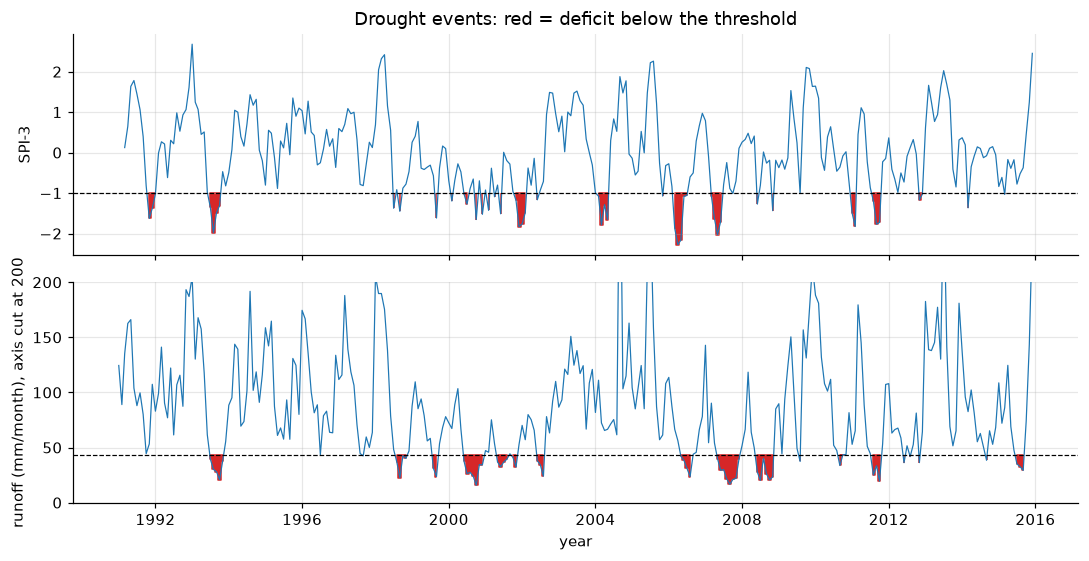

In [6]:
# Figure 2: the runs on the Chattooga, rain (SPI-3) and river (monthly runoff)
fig, ax = plt.subplots(2, 1, figsize=(10, 5.2), sharex=True)
ax[0].plot(spi3, color="tab:blue", lw=0.8); ax[0].axhline(-1, color="k", ls="--", lw=0.8)
ax[0].fill_between(spi3.index, spi3, -1, where=spi3 < -1, color="tab:red", step="mid")
ax[0].set_ylabel("SPI-3"); ax[0].set_title("Drought events: red = deficit below the threshold")
ax[1].plot(q, color="tab:blue", lw=0.8); ax[1].axhline(x0_q, color="k", ls="--", lw=0.8)
ax[1].fill_between(q.index, q, x0_q, where=q < x0_q, color="tab:red", step="mid")
ax[1].set_ylabel("runoff (mm/month), axis cut at 200"); ax[1].set_ylim(0, 200); ax[1].set_xlabel("year")
plt.tight_layout(); plt.show()

The rain index produces many short events: 27 runs below SPI-3 $=-1$, 17 of them a single month. The river filters them out. With Q80 the flow gives 20 events in 25 years, mostly in late summer and autumn, when the flow is lowest anyway. The largest, May to December 2007, lasted 8 months with a deficit of 128.8 mm, about 69 million m3 of water that the river did not carry; 2000 and 2008 come next. These are the known south-eastern US droughts we saw in Lecture 26. The mean inter-arrival time is about 14 months, but the events cluster in dry years.

Pooling with $t_c=1$ month merges the runs that are separated by a single month above the threshold:

In [7]:
def pool(ev, tc=1):
    """Merge events separated by tc months or less (inter-event time method): D spans both, S is the sum."""
    out = [ev.iloc[0][["start", "end", "S"]].to_dict()]
    for _, e in ev.iloc[1:].iterrows():
        gap = (e.start.year - out[-1]["end"].year) * 12 + e.start.month - out[-1]["end"].month - 1
        if gap <= tc:
            out[-1]["end"] = e.end; out[-1]["S"] += e.S
        else:
            out.append(e[["start", "end", "S"]].to_dict())
    p = pd.DataFrame(out)
    p["D"] = (p.end.dt.year - p.start.dt.year) * 12 + p.end.dt.month - p.start.dt.month + 1
    p["I"] = p.S / p.D
    return p

for name, ev in (("SPI-3", ev_spi), ("flow", ev_q)):
    print(f"{name}: {len(ev)} events before pooling, {len(pool(ev))} after (tc = 1 month)")

SPI-3: 27 events before pooling, 22 after (tc = 1 month)
flow: 20 events before pooling, 18 after (tc = 1 month)


For the river, pooling changes little (two pairs merge: 2001 and 2012). For SPI-3 it matters more, because the rain index crosses the threshold back and forth. From here on we use the 20 unpooled streamflow events.

## 3) Drought frequency

**Empirical return period.** Sort the events by severity. If $m$ events in $N_y$ years had a severity of at least $s$, an event that severe happens on average every

$$T=\frac{N_y}{m}\ \text{years}.$$

The same rule works for duration (count events with $D$ at least $d$).

**A fitted distribution.** To read severities rarer than the record, fit a distribution to the event severities. The simplest is the exponential (Lecture 17), whose only parameter is the mean severity $\bar S$: the chance that an event exceeds $s$ is $\exp(-s/\bar S)$. With $\lambda=n_e/N_y$ events per year, events larger than $s$ occur $\lambda\exp(-s/\bar S)$ times a year, so

$$T(s)=\frac{1}{\lambda\,\exp(-s/\bar S)}\qquad\Longleftrightarrow\qquad s_T=\bar S\,\ln(\lambda T)\quad(\lambda T>1).$$

A gamma or a Weibull often fits severities better; the exponential keeps the arithmetic visible.

n_e = 20, N_y = 25 yr, lambda = 0.80 events/yr, S_bar = 35.4 mm
check with scipy (exponential MLE, loc = 0): scale = 35.4
T =  2 yr: s_T =   16.6 mm
T =  5 yr: s_T =   49.1 mm
T = 10 yr: s_T =   73.6 mm
T = 25 yr: s_T =  106.0 mm
T = 50 yr: s_T =  130.6 mm
largest event, S = 128.8 mm: empirical T = 25 yr, exponential T = 48 yr
events with D >= 6 months: 3, empirical T = 8.3 yr


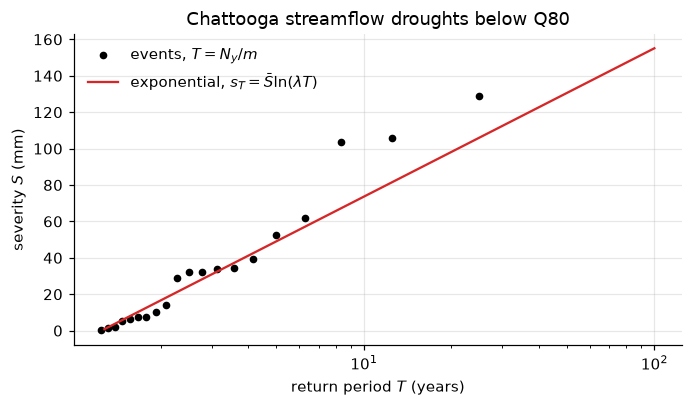

In [8]:
ne = len(ev_q); lam = ne / Ny; S_bar = ev_q.S.mean()
S_sorted = np.sort(ev_q.S.values)[::-1]
T_emp = Ny / np.arange(1, ne + 1)                          # m = 1 for the largest
print(f"n_e = {ne}, N_y = {Ny:.0f} yr, lambda = {lam:.2f} events/yr, S_bar = {S_bar:.1f} mm")
print("check with scipy (exponential MLE, loc = 0): scale =", round(stats.expon.fit(ev_q.S, floc=0)[1], 1))
for T in (2, 5, 10, 25, 50):
    print(f"T = {T:2d} yr: s_T = {S_bar * np.log(lam * T):6.1f} mm")
print(f"largest event, S = {S_sorted[0]:.1f} mm: empirical T = {T_emp[0]:.0f} yr, exponential T = {1 / (lam * np.exp(-S_sorted[0] / S_bar)):.0f} yr")
print(f"events with D >= 6 months: {(ev_q.D >= 6).sum()}, empirical T = {Ny / (ev_q.D >= 6).sum():.1f} yr")

# Figure 3: severity against return period
TT = np.logspace(np.log10(1 / lam) + 0.01, 2, 100)
fig, ax = plt.subplots(figsize=(6.4, 3.8))
ax.semilogx(T_emp, S_sorted, "ko", ms=4, label="events, $T=N_y/m$")
ax.semilogx(TT, S_bar * np.log(lam * TT), "tab:red", label=r"exponential, $s_T=\bar S\ln(\lambda T)$")
ax.set_xlabel("return period $T$ (years)"); ax.set_ylabel("severity $S$ (mm)"); ax.legend(frameon=False)
ax.set_title("Chattooga streamflow droughts below Q80"); plt.tight_layout(); plt.show()

The exponential follows the small and medium events but lies below the three largest (2000, 2007, 2008), a sign that the tail is heavier than exponential. It gives a 10-year severity of about 74 mm and a 25-year severity of about 106 mm. The largest event (129 mm) sits at $T=25$ years by the plotting rule, while the exponential puts it near 48 years: with one event in 25 years, either answer is very uncertain. In practice we would want a longer record, several stations, or regional pooling.

Duration and severity are linked (long droughts are usually severe), so a full analysis asks for their *joint* probability. This bivariate analysis is usually done with copulas (Shiau 2006), which join the two distributions into one.

## 4) Climate change and droughts

Warming changes droughts in two ways. Rainfall may change (up or down, depending on the region; Lectures 14 and 18 show how to get such changes from scenarios). And **evaporation demand rises with temperature everywhere**, so the same rain leaves less water. The SPI sees only rain and misses the second effect; the SPEI of Lecture 26 sees both.

A simple illustration with our data. The PET in the dataset is the Oudin et al. (2005) formula, which is proportional to $T+5$ (with $T$ in degC, and zero when $T\le -5$). Warming every day by $\Delta T$ therefore multiplies each day's PET by $(T+5+\Delta T)/(T+5)$. We add $\Delta T=2$ degC, keep the rain unchanged, and compute the SPEI-12 of the warmer climate **with the distribution fitted to the present climate**, so that the index measures dryness relative to today. *This is an illustration, not a projection:* real PET also depends on humidity, wind and plants, and temperature-only formulas tend to overstate the increase.

annual PET: 974 mm now, 1064 mm with +2 degC (9.2 %)
SPEI-12 now     : mean +0.01, months <= -1: 18 %, events 11, drought months 53, longest 24 months, largest S 10.8
SPEI-12 +2 degC : mean -0.27, months <= -1: 28 %, events 13, drought months 82, longest 33 months, largest S 20.4


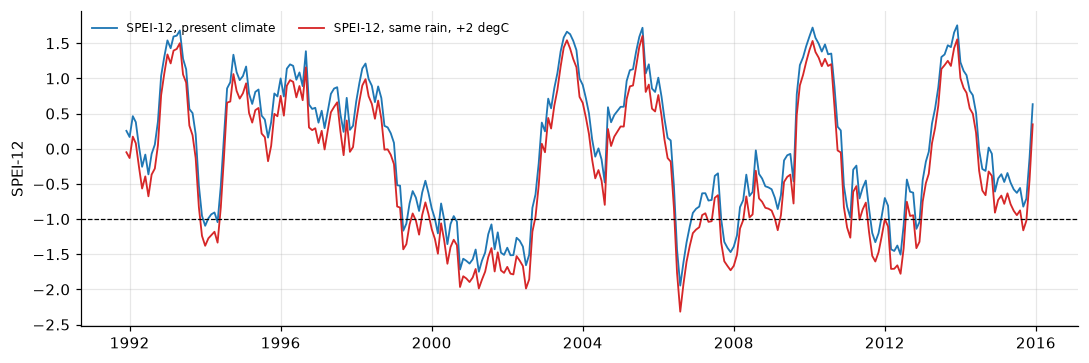

In [9]:
def loglogistic_fit(w):                 # Lecture 26: log-logistic by probability-weighted moments
    w = np.sort(w); F = (np.arange(1, len(w) + 1) - 0.35) / len(w)
    w0, w1, w2 = (np.mean((1 - F) ** s * w) for s in (0, 1, 2))
    shape = (2 * w1 - w0) / (6 * w1 - w0 - 6 * w2)
    g = gamma_fn(1 + 1 / shape) * gamma_fn(1 - 1 / shape)
    scale = (w0 - 2 * w1) * shape / g
    return scale, shape, w0 - scale * g

def spei(W, k, W_fit):
    """SPEI-k of W, with one log-logistic per calendar month fitted to W_fit (the present climate)."""
    wk, wf = W.rolling(k).sum(), W_fit.rolling(k).sum()
    out = pd.Series(np.nan, index=W.index)
    for month in range(1, 13):
        sel = wk.index.month == month
        scale, shape, loc = loglogistic_fit(wf[sel].dropna().values)
        out[sel] = stats.norm.ppf(np.clip(stats.fisk.cdf(wk[sel].values, shape, loc=loc, scale=scale), 1e-6, 1 - 1e-6))
    return out

dT = 2.0
factor = np.where(df.tmean_c + 5 > 0, (df.tmean_c + 5 + dT) / (df.tmean_c + 5), 1.0)
pet_warm = (df.pet_mm * factor).resample("MS").sum()
W_now, W_warm = mon.prcp_mm - mon.pet_mm, mon.prcp_mm - pet_warm
spei_now, spei_warm = spei(W_now, 12, W_now), spei(W_warm, 12, W_now)
print(f"annual PET: {mon.pet_mm.sum() / Ny:.0f} mm now, {pet_warm.sum() / Ny:.0f} mm with +{dT:.0f} degC ({100 * (pet_warm.sum() / mon.pet_mm.sum() - 1):.1f} %)")
for name, s in (("now", spei_now), ("+2 degC", spei_warm)):
    e = runs(s, -1.0)
    print(f"SPEI-12 {name:8s}: mean {s.mean():+.2f}, months <= -1: {100 * (s.dropna() <= -1).mean():.0f} %, "
          f"events {len(e)}, drought months {e.D.sum()}, longest {e.D.max()} months, largest S {e.S.max():.1f}")

# Figure 4
fig, ax = plt.subplots(figsize=(10, 3.4))
ax.plot(spei_now, color="tab:blue", lw=1.2, label="SPEI-12, present climate")
ax.plot(spei_warm, color="tab:red", lw=1.2, label="SPEI-12, same rain, +2 degC")
ax.axhline(-1, color="k", lw=0.8, ls="--"); ax.set_ylabel("SPEI-12"); ax.legend(frameon=False, fontsize=8, loc="upper left", ncol=2)
plt.tight_layout(); plt.show()

Two degrees of warming raise the annual PET by about 9 %. With exactly the same rain, the SPEI-12 shifts down by about 0.28 on average, the share of months at or below $-1$ rises from 18 % to 28 %, and the 2000 to 2002 drought grows into one run of 33 months (24 months now) whose severity is about twice the present largest. The SPI would show no change at all, because the rain did not change. This is why drought studies under climate change use indices that include evaporation demand, and why *invisible* drought (Lecture 26) becomes more common in a warmer world. To add a rainfall change as well, scale the monthly rain by the change from a scenario (the delta change of Lectures 14 and 18) before computing $W$.

## 5) Drought declaration and management in India

India's procedure is set out in the **Manual for Drought Management** (Ministry of Agriculture and Farmers Welfare, Government of India, 2016, updated in 2020). It replaced older practice, which leaned mostly on rainfall deficit and crop-yield estimates, with a stepwise check of several indicators. The outline below describes the structure; the exact thresholds, weights and dates differ between editions, so use the current manual for real decisions.

1. **Mandatory indicators (rainfall).** For each district or block: the rainfall departure from normal (the IMD classes of Lecture 26) and the dry spell (a long run of days or weeks with very little rain during the season); the 2016 edition also lists the SPI. If these indicators show a deficit, the drought trigger is set and the next step follows.
2. **Impact indicators**, in four groups:
   - *agriculture*: area sown compared with normal, crop condition;
   - *remote sensing of vegetation*: NDVI (a satellite measure of how green the vegetation is), VCI (NDVI compared with its own range in past years at that place), and a water index;
   - *soil moisture*: for example a moisture adequacy index;
   - *hydrology*: reservoir storage, groundwater levels, streamflow.
3. **Severity.** If enough impact indicators also show drought, the area is assessed as in **moderate** or **severe** drought, depending on how many of them reach the severe range.
4. **Ground truthing.** A field survey of sample villages checks crop condition and loss before the final decision, especially for severe drought.
5. **Declaration.** The **state government** declares drought by notification for the affected districts, talukas or blocks, within the season's time limits (for kharif and rabi separately). A declaration opens relief from the State Disaster Response Fund; for severe drought the state can ask for central assistance from the National Disaster Response Fund, after a central team has assessed the situation.

**Who does what.** IMD supplies rainfall, normals, departures, dry spells, SPI maps and forecasts. The Mahalanobis National Crop Forecast Centre supplies satellite-based crop and vegetation assessments. The Central Water Commission reports reservoir storage and the Central Ground Water Board groundwater levels. The **district** administration collects the indicators, carries out the field survey and runs relief; the **state** declares; the **Ministry of Agriculture and Farmers Welfare** coordinates at the national level.

**Mitigation**, before and during a drought:

- *crop contingency plans* for each district (prepared with ICAR-CRIDA), listing alternative crops and varieties if the monsoon is late or breaks;
- *drinking water first*: tankers, deeper or new wells, protected reservoir reserves;
- *groundwater*: limits on pumping, recharge structures, community management;
- *drought proofing*: watershed development, farm ponds and check dams, micro-irrigation, afforestation, often through rural employment works, so that the next drought hurts less;
- *risk transfer and support*: crop insurance, fodder banks and cattle camps, employment and food programmes.

The indices of Lectures 26 and 27 sit inside this procedure: rainfall departure and SPI start it, vegetation and hydrological indicators confirm it, and duration, severity and return period tell planners how much storage and support to prepare.

## Summary

- The theory of runs turns an index into events: below a threshold $x_0$, each run has duration $D$, severity $S=\sum(x_0-x_t)$, intensity $I=S/D$ and inter-arrival time $L$; short gaps can be pooled. Hand example: three events, the largest with $D=5$ months, $S=44$ mm, $I=8.8$ mm/month and $T=1.5$ years.
- On the Chattooga, the river gives 20 droughts below Q80 in 25 years; the largest (2007) lasted 8 months with a 128.8 mm deficit.
- Return period: $T=N_y/m$ from the record; with an exponential, $s_T=\bar S\ln(\lambda T)$. The 25-year severity is about 106 mm; single extreme events remain very uncertain.
- With the same rain, 2 degC of warming raises PET by about 9 % and makes the SPEI-12 drought months rise from 18 % to 28 %.
- India declares drought in steps: rainfall indicators trigger, impact indicators confirm, field surveys verify, the state declares; mitigation ranges from contingency crop plans to long-term drought proofing.

## Check your understanding

1. In the hand example, what happens to the events if the threshold is raised to 35 mm? Which quantity, $D$ or $S$, is more sensitive to the threshold?
2. Why does the rain index (SPI-3) give more and shorter events than the streamflow series?
3. With $\lambda=0.8$ events a year and $\bar S=35.4$ mm, what is the 50-year severity? Why does the formula fail for $T$ below $1/\lambda$?

## Try it yourself

- Repeat the Chattooga analysis with Q90 and with $x_0=0$ for the SPI-3. How do the number of events and the largest severity change?
- Replace the exponential by a gamma (`stats.gamma.fit(S, floc=0)`) and compare the 25-year severity.
- Change the rain by $-10$ % together with $+2$ degC (a simple delta change, Lecture 18) and recompute the share of SPEI-12 months at or below $-1$.

```{note} Sources
Written for **CE524 Applied Hydroclimatology**. Theory of runs: Yevjevich, V. (1967). *An objective approach to definitions and investigations of continental hydrologic droughts*. Hydrology Paper 23, Colorado State University; Mishra, A. K., & Singh, V. P. (2010). A review of drought concepts. *J. Hydrology, 391*, 202&ndash;216. Pooling: Tallaksen, L. M., Madsen, H., & Clausen, B. (1997). On the definition and modelling of streamflow drought duration and deficit volume. *Hydrological Sciences Journal, 42*, 15&ndash;33. Copulas: Shiau, J. T. (2006). Fitting drought duration and severity with two-dimensional copulas. *Water Resources Management, 20*, 795&ndash;815. SPI and SPEI: McKee et al. (1993), WMO (2012) and Vicente-Serrano et al. (2010), see Lecture 26. PET: Oudin, L., et al. (2005). Which potential evapotranspiration input for a lumped rainfall-runoff model? *J. Hydrology, 303*, 290&ndash;306. India: Ministry of Agriculture and Farmers Welfare, Government of India (2016; updated 2020). *Manual for Drought Management*. New Delhi. Data: Chattooga River, Daymet v4 and USGS NWIS (see Lecture 7). The explanations, hand example, workbook and figures were made for this course. Related lectures: 14, 17, 18, 26.

Text under CC BY-SA 4.0, code additionally under the MIT License; full attribution in [CREDITS.md](https://github.com/drvivekhydro/hydroclimatology/blob/main/CREDITS.md).
```